In [1]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.1 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 32.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.3 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 72.3 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.9.41
    Uninstalling nvidia-nvjitlink-cu12-12.9.41:
      Successfully uninstalled nvidia-nvjitlink-cu12-12.9.41
  Attempting uninstall: nvidia-curand-cu12
    Found exi

In [2]:
import yaml

# Use full absolute paths for Kaggle input dataset
data_yaml = {
    'train': '/kaggle/input/vaid-dataset/aerial_images/train/images',
    'val': '/kaggle/input/vaid-dataset/aerial_images/valid/images',
    'test': '/kaggle/input/vaid-dataset/aerial_images/test/images',  # optional
    'nc': 7,
    'names': ['sedan', 'minibus', 'truck', 'pickup', 'bus', 'cement truck', 'trailer']
}

# Save it to a writable location
yaml_path = '/kaggle/working/data.yaml'
with open(yaml_path, 'w') as f:
    yaml.dump(data_yaml, f)

print(f"Corrected data.yaml saved to: {yaml_path}")


Corrected data.yaml saved to: /kaggle/working/data.yaml


In [3]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="/kaggle/working/data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    project="/kaggle/working",
    name="vaid-dataset-training"
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 49.7M/49.7M [00:00<00:00, 240MB/s]


Ultralytics 8.3.133 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=vaid-dataset-training, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.

100%|██████████| 755k/755k [00:00<00:00, 17.7MB/s]


Overriding model.yaml nc=80 with nc=7

                   from  n    params  module                                       arguments                     
  0                  -1  1      1392  ultralytics.nn.modules.conv.Conv             [3, 48, 3, 2]                 
  1                  -1  1     41664  ultralytics.nn.modules.conv.Conv             [48, 96, 3, 2]                
  2                  -1  2    111360  ultralytics.nn.modules.block.C2f             [96, 96, 2, True]             
  3                  -1  1    166272  ultralytics.nn.modules.conv.Conv             [96, 192, 3, 2]               
  4                  -1  4    813312  ultralytics.nn.modules.block.C2f             [192, 192, 4, True]           
  5                  -1  1    664320  ultralytics.nn.modules.conv.Conv             [192, 384, 3, 2]              
  6                  -1  4   3248640  ultralytics.nn.modules.block.C2f             [384, 384, 4, True]           
  7                  -1  1   1991808  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 74.9MB/s]


... (67 outputs left out)

                   all         49        152      0.942       0.98      0.995      0.851
                 sedan         48        124      0.976      0.984      0.994      0.802
               minibus         11         15      0.981          1      0.995      0.894
                 truck          5          5       0.95          1      0.995      0.808
                pickup          5          7          1      0.915      0.995      0.757
                   bus          1          1      0.803          1      0.995      0.995


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


Speed: 0.1ms preprocess, 7.4ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/vaid-dataset-training


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bb36f10c550>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

# **Step 2: Extract Trajectories / Count-Maps per Frame**

## **Step 2A: Load Trained Model & Run Inference**

In [5]:
from ultralytics import YOLO
import os
from pathlib import Path

# Load your trained model
model = YOLO('/kaggle/working/vaid-dataset-training/weights/best.pt')

# Define test image directory and output path
test_dir = '/kaggle/input/vaid-dataset/aerial_images/test/images'
output_dir = '/kaggle/working/inference_outputs'
os.makedirs(output_dir, exist_ok=True)

# Run inference on all test images and save results
results = model.predict(source=test_dir, save=True, save_txt=True, project=output_dir, name="yolo_preds")



image 1/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000004.jpg: 384x640 3 sedans, 42.0ms
image 2/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000013.jpg: 384x640 4 sedans, 25.0ms
image 3/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000014.jpg: 384x640 4 sedans, 23.5ms
image 4/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000016.jpg: 384x640 3 sedans, 23.6ms
image 5/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000017.jpg: 384x640 3 sedans, 23.5ms
image 6/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000045.jpg: 384x640 3 sedans, 23.1ms
image 7/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000048.jpg: 384x640 1 sedan, 20.3ms
image 8/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000053.jpg: 384x640 1 sedan, 20.3ms
image 9/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000058.jpg: 384x640 1 sedan, 20.3ms
image 10/50 /kaggle/input/vaid-dataset/aerial_images/test/images/000072.jpg: 384x640 1 sedan,

In [15]:
import os
label_dir = "/kaggle/working/inference_outputs/yolo_preds/labels"
print("Predicted label files:", os.listdir(label_dir)[:5])


Predicted label files: ['000373.txt', '000371.txt', '000116.txt', '000222.txt', '000766.txt']


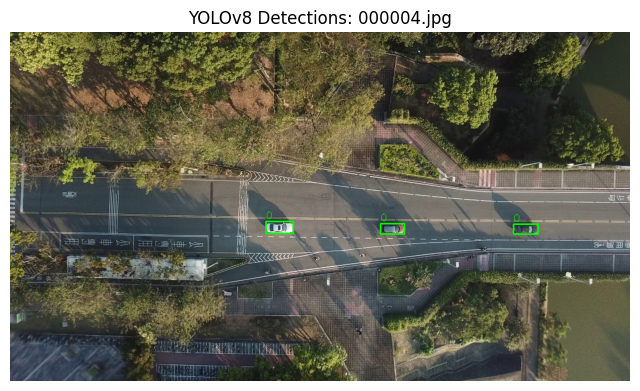

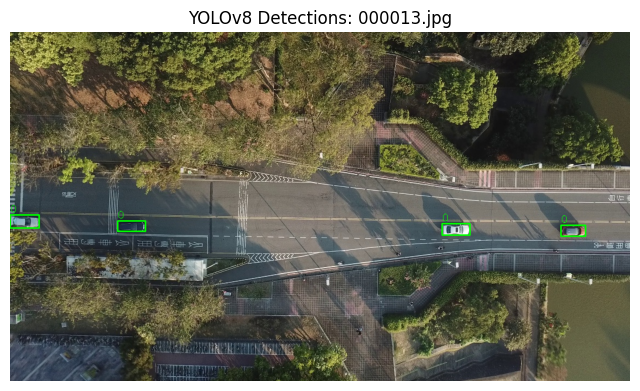

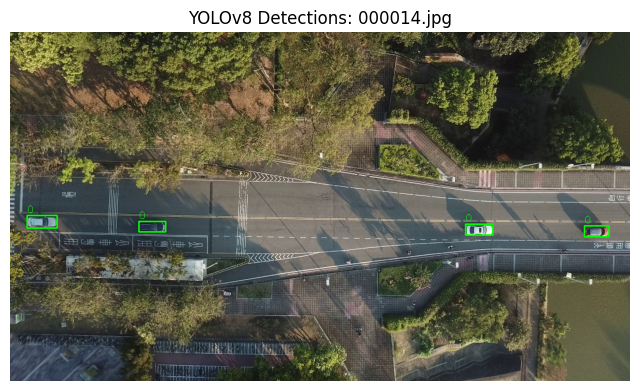

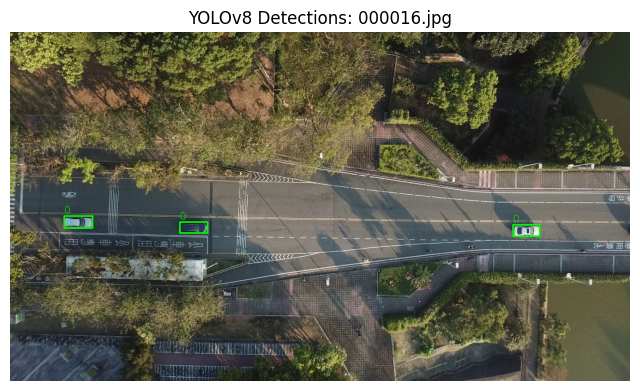

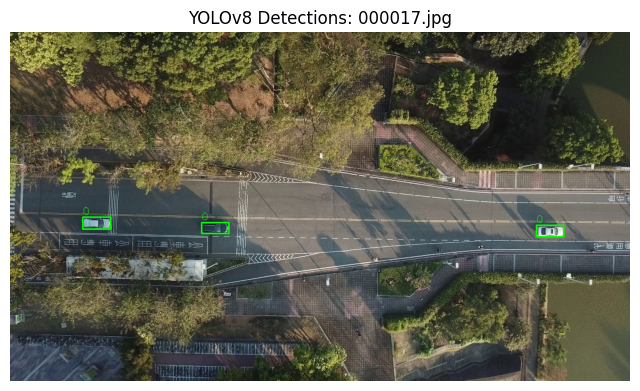

In [22]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Define label and image directories
label_dir = Path('/kaggle/working/inference_outputs/yolo_preds/labels')
img_dir = Path('/kaggle/input/vaid-dataset/aerial_images/test/images')

# Get image paths that have predictions
label_files = sorted(label_dir.glob("*.txt"))
predicted_imgs = [img_dir / (f.stem + '.jpg') for f in label_files]

# Loop through and visualize
for img_path in predicted_imgs[:5]:  # show 5 examples
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    label_path = label_dir / f"{img_path.stem}.txt"
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue  # skip malformed lines
            cls, x, y, bw, bh = map(float, parts)
            # Convert normalized to pixel coordinates
            x1 = int((x - bw / 2) * w)
            y1 = int((y - bh / 2) * h)
            x2 = int((x + bw / 2) * w)
            y2 = int((y + bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(img, f'{int(cls)}', (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 1)

    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"YOLOv8 Detections: {img_path.name}")
    plt.show()


## **Step 2B: Track Vehicles Across Frames (Trajectory Extraction)**

In [ ]:
!git clone https://github.com/ifzhang/ByteTrack.git /kaggle/working/bytetrack
!pip install -q cython_bbox lap
!pip install -q git+https://github.com/bbrattoli/deep_sort_pytorch.git


Cloning into '/kaggle/working/bytetrack'...
remote: Enumerating objects: 2007, done.
remote: Total 2007 (delta 0), reused 0 (delta 0), pack-reused 2007 (from 1)
Receiving objects: 100% (2007/2007), 79.60 MiB | 44.84 MiB/s, done.
Resolving deltas: 100% (1141/1141), done.
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 20.7 MB/s eta 0:00:0000:010:01
Username for 'https://github.com': 

In [25]:
!rm -rf /kaggle/working/sort  # clear old broken clone
!git clone https://github.com/abewley/sort.git /kaggle/working/sort


Cloning into '/kaggle/working/sort'...
remote: Enumerating objects: 208, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 208 (delta 2), reused 1 (delta 1), pack-reused 203 (from 2)
Receiving objects: 100% (208/208), 1.21 MiB | 16.25 MiB/s, done.
Resolving deltas: 100% (74/74), done.


In [ ]:
import sys
sys.path.append("/kaggle/working/bytetrack")

from yolox.tracker.byte_tracker import BYTETracker
from yolox.tracking_utils.timer import Timer


In [13]:
import numpy as np
import pandas as pd
from pathlib import Path

label_dir = Path('/kaggle/working/inference_outputs/yolo_preds/labels')
img_dir = Path('/kaggle/input/vaid-dataset/aerial_images/test/images')

# ByteTrack params
class Args:
    track_thresh = 0.3
    track_buffer = 30
    match_thresh = 0.8
    min_box_area = 10
    mot20 = False

tracker = BYTETracker(Args(), frame_rate=30)

trajectories = []
image_paths = sorted(img_dir.glob("*.jpg"))

for frame_id, img_path in enumerate(image_paths):
    txt_path = label_dir / f"{img_path.stem}.txt"
    detections = []

    if txt_path.exists():
        with open(txt_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls, x, y, w, h = map(float, parts)
                x1 = (x - w / 2) * 640
                y1 = (y - h / 2) * 640
                bw = w * 640
                bh = h * 640
                conf = 1.0
                detections.append([x1, y1, bw, bh, conf])

    detections = np.array(detections)
    online_targets = tracker.update(detections, (640, 640), (640, 640))

    for t in online_targets:
        tlwh = t.tlwh
        track_id = t.track_id
        cx = tlwh[0] + tlwh[2] / 2
        cy = tlwh[1] + tlwh[3] / 2
        trajectories.append((int(track_id), frame_id, cx, cy))

# Save tracked data
df_traj = pd.DataFrame(trajectories, columns=['track_id', 'frame', 'x', 'y'])
df_traj.to_csv('/kaggle/working/trajectories.csv', index=False)
print("✅ ByteTrack trajectories saved.")


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/yolo_inference/yolo_preds/labels'

In [12]:
import pandas as pd

# Load trajectory data
df_traj = pd.read_csv('/kaggle/working/trajectories.csv')

# Choose a frame for background
base_frame_path = sorted(list(img_dir.glob("*.jpg")))[0]
img = cv2.imread(str(base_frame_path))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Draw past points from trajectories
plt.figure(figsize=(8, 8))
plt.imshow(img)
for track_id in df_traj['track_id'].unique()[:10]:
    traj = df_traj[df_traj['track_id'] == track_id]
    plt.plot(traj['x'], traj['y'], label=f'ID {track_id}')
plt.title('Object Trajectories over First Frame')
plt.legend()
plt.gca().invert_yaxis()
plt.axis('off')
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/trajectories.csv'

In [ ]:
(track_id, frame_id, x, y)


## **Step 2C: Create Count-Maps Per Frame**

Assume an image grid (e.g. 8x8), you can bin detections:

In [ ]:
import pandas as pd

# Convert to dataframe
df = pd.DataFrame(trajectories, columns=['id', 'frame', 'x', 'y'])

# Define grid size and image size
grid_size = (8, 8)
image_size = (640, 640)

df['x_bin'] = (df['x'] / (image_size[0] / grid_size[0])).astype(int)
df['y_bin'] = (df['y'] / (image_size[1] / grid_size[1])).astype(int)

count_maps = (
    df.groupby(['frame', 'y_bin', 'x_bin'])
    .size()
    .unstack(fill_value=0)
)

# You can visualize or save count_maps per frame
import matplotlib.pyplot as plt

def plot_count_map(frame_id):
    frame_data = df[df['frame'] == frame_id]
    heatmap = np.zeros(grid_size)
    for _, row in frame_data.iterrows():
        if 0 <= row['y_bin'] < grid_size[0] and 0 <= row['x_bin'] < grid_size[1]:
            heatmap[int(row['y_bin']), int(row['x_bin'])] += 1
    plt.imshow(heatmap, cmap='hot', interpolation='nearest')
    plt.title(f'Frame {frame_id}')
    plt.show()

plot_count_map(0)
